
# Subset smoke test for the XGBoost LOO pipeline

This notebook runs the provided `cv_pipeline_loo` pipeline on a small subset of your data, then saves and displays the generated output files.

Expected project layout:

```text
project/
  pipeline_functions.py
  data/
    transcriptomics_filtered.joblib
    proteomics_matched.joblib   # also checks proteomics_matched.jpoblib for the typo
```

The defaults are intentionally small so the notebook is useful as a quick sanity check. After confirming it works, increase `MAX_SAMPLES`, `SELECT_K`, or switch `TUNING_STRATEGY` from `"once"` to `"nested"`.


In [1]:
# >>> pRNA figure routing (added by the pRNA update; keep as the first code cell)
# Every figure is shown inline. Every file written with savefig (png, pdf, svg) is redirected to
# figures_pdf/<notebook name>/ next to this notebook; sub-folders of the original path are preserved.
import os as _fig_os
from pathlib import Path as _FigPath
import matplotlib as _fig_mpl
import matplotlib.pyplot as _fig_plt
from matplotlib.figure import Figure as _FigFigure

NOTEBOOK_NAME = "xgb_loo_smoke_test"
FIG_DIR = (_FigPath.cwd() / "figures_pdf" / NOTEBOOK_NAME).resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _route_figure_path(fname):
    p = _FigPath(_fig_os.fspath(fname))
    full = p if p.is_absolute() else (_FigPath.cwd() / p)
    try:
        full.resolve().relative_to(FIG_DIR)
        return fname                                  # already inside this notebook's figure folder
    except ValueError:
        pass
    try:
        rel = _FigPath(_fig_os.path.relpath(full.resolve(), _FigPath.cwd()))
    except ValueError:                                # e.g. another drive on Windows
        rel = _FigPath(p.name)
    parts = [x for x in rel.parts if x not in ("..", ".", "figures_pdf", NOTEBOOK_NAME)]
    target = FIG_DIR.joinpath(*parts) if parts else FIG_DIR / p.name
    target.parent.mkdir(parents=True, exist_ok=True)
    return target


if not getattr(_FigFigure.savefig, "_prna_routed", False):
    _fig_orig_savefig = _FigFigure.savefig

    def _fig_routed_savefig(self, fname, *args, **kwargs):
        if isinstance(fname, (str, bytes, _FigPath)) or hasattr(fname, "__fspath__"):
            fname = _route_figure_path(fname)
        return _fig_orig_savefig(self, fname, *args, **kwargs)

    _fig_routed_savefig._prna_routed = True
    _FigFigure.savefig = _fig_routed_savefig

    _fig_orig_close = _fig_plt.close

    def _fig_close_and_show(fig=None):
        """Display figures that are closed before Jupyter could render them, then close."""
        import inspect as _fig_inspect
        _caller = _fig_inspect.currentframe().f_back
        _caller_mod = (_caller.f_globals.get("__name__", "") if _caller is not None else "")
        if _caller_mod.startswith(("matplotlib", "ipykernel")):   # backend housekeeping, not user code
            return _fig_orig_close(fig)
        if "inline" in str(_fig_mpl.get_backend()).lower():
            from IPython.display import display as _fig_display
            open_nums = set(_fig_plt.get_fignums())
            if fig is None:
                figs = [_fig_plt.gcf()] if open_nums else []
            elif isinstance(fig, str) and fig == "all":
                figs = [_fig_plt.figure(n) for n in sorted(open_nums)]
            elif isinstance(fig, _FigFigure):
                figs = [fig] if getattr(fig, "number", None) in open_nums else []
            elif isinstance(fig, int):
                figs = [_fig_plt.figure(fig)] if fig in open_nums else []
            else:
                figs = []
            for _f in figs:
                if not getattr(_f, "_prna_displayed", False):
                    _f._prna_displayed = True
                    _fig_display(_f)
        return _fig_orig_close(fig)

    _fig_plt.close = _fig_close_and_show

    _fig_orig_show = _fig_plt.show

    def _fig_show_and_mark(*args, **kwargs):
        for _n in _fig_plt.get_fignums():                    # shown now -> never re-displayed on close
            _fig_plt.figure(_n)._prna_displayed = True
        return _fig_orig_show(*args, **kwargs)

    _fig_plt.show = _fig_show_and_mark

print("Figures are saved to", FIG_DIR)

Figures are saved to C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\pipeline_xgb_loo\figures_pdf\xgb_loo_smoke_test


In [2]:

from pathlib import Path
import os
import sys
import json
import warnings
import re
from datetime import datetime

import numpy as np
import pandas as pd
from joblib import load, dump
from IPython.display import display, FileLink, Markdown

warnings.filterwarnings("default")
np.random.seed(42)

# --- Locate project/data folders ---
PROJECT_DIR = Path.cwd().resolve()

# Add common source locations so `pipeline_functions.py` can be imported.
for candidate in [PROJECT_DIR, PROJECT_DIR / "src", PROJECT_DIR / "scripts", PROJECT_DIR / "notebooks"]:
    if candidate.exists() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))

# DATA_DIR can be overridden before launching Jupyter, e.g. DATA_DIR=/path/to/data jupyter lab
DATA_DIR = Path(os.environ.get("DATA_DIR", PROJECT_DIR.parent / "data")).resolve()
if not DATA_DIR.exists() and (PROJECT_DIR.parent / "data").exists():
    DATA_DIR = (PROJECT_DIR.parent / "data").resolve()

X_PATH_CANDIDATES = [
    DATA_DIR / "transcriptomics_filtered.joblib",
]
Y_PATH_CANDIDATES = [
    DATA_DIR / "proteomics_matched.joblib",
    DATA_DIR / "proteomics_matched.jpoblib",  # typo fallback mentioned in prompt
]

def first_existing(paths):
    for path in paths:
        if path.exists():
            return path
    return None

X_PATH = first_existing(X_PATH_CANDIDATES)
Y_PATH = first_existing(Y_PATH_CANDIDATES)

print(f"PROJECT_DIR: {PROJECT_DIR}")
print(f"DATA_DIR:    {DATA_DIR}")
print(f"X_PATH:      {X_PATH}")
print(f"Y_PATH:      {Y_PATH}")

if X_PATH is None:
    raise FileNotFoundError(f"Could not find transcriptomics_filtered.joblib under {DATA_DIR}")
if Y_PATH is None:
    raise FileNotFoundError(f"Could not find proteomics_matched.joblib or proteomics_matched.jpoblib under {DATA_DIR}")

try:
    from pipeline_functions import cv_pipeline_loo, predict_with_artifact
except Exception as exc:
    raise ImportError(
        "Could not import cv_pipeline_loo from pipeline_functions.py. "
        "Place this notebook in the same folder as pipeline_functions.py, "
        "or add that folder to sys.path above."
    ) from exc

print("Imported cv_pipeline_loo successfully.")


PROJECT_DIR: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\pipeline_xgb_loo
DATA_DIR:    C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data
X_PATH:      C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data\transcriptomics_filtered.joblib
Y_PATH:      C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data\proteomics_matched.joblib
Imported cv_pipeline_loo successfully.



## 1. Load and inspect the input matrices

The pipeline expects:

- `transcriptomics_filtered`: samples x genes
- `proteomics_matched`: proteins x samples, with a legacy fallback for samples x proteins


In [3]:

print("Loading data...")
X = load(X_PATH)
Y = load(Y_PATH)

if not isinstance(X, pd.DataFrame):
    X = pd.DataFrame(X)
if not isinstance(Y, pd.DataFrame):
    Y = pd.DataFrame(Y)

X.index.name, X.columns.name = "samples", "genes"
Y.index.name, Y.columns.name = "proteins", "samples"

print(f"X shape, samples x genes: {X.shape}")
print(f"Y shape, proteins x samples expected: {Y.shape}")
print(f"X memory: {X.memory_usage(deep=True).sum() / 1e6:.2f} MB")
print(f"Y memory: {Y.memory_usage(deep=True).sum() / 1e6:.2f} MB")

print("\nTranscriptomics preview:")
display(X.iloc[:5, :5])

print("\nProteomics preview:")
display(Y.iloc[:5, :5])


Loading data...
X shape, samples x genes: (369, 22614)
Y shape, proteins x samples expected: (369, 5113)
X memory: 66.78 MB
Y memory: 15.12 MB

Transcriptomics preview:


genes,A1BG,A1BG-AS1,A1CF,A2M,A2ML1
samples,,,,,
MDAMB468_BREAST,2.689299,2.954196,0.014355,3.329124,0.443607
SH4_SKIN,4.980025,3.583760,0.000000,8.405099,0.000000
AU565_BREAST,2.518535,2.269033,0.014355,1.275007,2.451541
KMRC1_KIDNEY,0.084064,0.070389,0.000000,0.137504,0.000000
CAL51_BREAST,4.729553,2.807355,0.014355,0.575312,0.713696



Proteomics preview:


samples,A2M,AAAS,AACS,AAGAB,AAK1
proteins,,,,,
MDAMB468_BREAST,-0.345562,-0.109405,0.370945,0.009639,0.005800
SH4_SKIN,1.642186,-0.283335,0.162102,-0.057517,0.760639
AU565_BREAST,-1.129114,0.024663,1.071283,-0.758048,-0.320451
KMRC1_KIDNEY,1.493333,-0.588886,0.404605,-0.210457,0.533949
CAL51_BREAST,0.274652,0.673324,-0.587890,-0.044001,-0.778679


In [4]:
X

genes,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,2.954196,0.014355,3.329124,0.443607,1.575312,5.311430,4.531069,0.056584,0.124328,...,4.139142,6.986752,2.192194,3.114367,4.250962,2.792855,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,3.583760,0.000000,8.405099,0.000000,0.111031,5.229972,4.095924,0.070389,0.014355,...,3.698218,6.113742,1.384050,2.659925,4.979111,0.014355,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,2.269033,0.014355,1.275007,2.451541,0.933573,6.011898,5.564378,1.618239,0.250962,...,4.235727,7.373909,0.632268,2.049631,3.471187,0.014355,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,0.070389,0.000000,0.137504,0.000000,2.903038,4.842476,3.357552,0.056584,0.124328,...,4.584361,6.704734,0.432959,1.021480,1.475085,0.485427,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,2.807355,0.014355,0.575312,0.713696,3.751678,6.262847,3.874797,0.056584,0.070389,...,4.835924,7.356496,1.700440,2.424922,3.884598,0.084064,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,0.389567,0.028569,0.028569,0.263034,4.168321,5.244887,5.409391,0.189034,2.446256,...,4.865919,7.543882,0.014355,0.028569,3.807355,0.790772,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,0.632268,0.042644,0.367371,0.150560,2.163499,6.280585,4.335569,0.014355,4.980939,...,5.210233,6.656067,2.137504,2.558268,3.754888,0.042644,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,2.185867,0.014355,0.000000,0.070389,0.042644,5.667608,3.218781,0.056584,0.000000,...,4.143230,7.929318,1.137504,1.835924,4.955127,0.056584,2.107688,5.816856,3.693766,5.030777



## 2. Configure a tiny subset run

These defaults prioritize finishing quickly over model quality. The notebook auto-selects a protein with enough non-missing values in the first `MAX_SAMPLES` aligned samples.


In [5]:

# --- Smoke-test settings ---
TARGET_PROTEIN = None       # Set to a string protein ID/name to override auto-selection.
MAX_SAMPLES = 10            # Small LOO run. Increase after smoke test passes.
SELECT_K = 50               # Top-K Spearman features. Use 0 to keep all features.
SPLITS = 3                  # Inner CV folds.
EARLY_STOPPING = 10         # Lower than production for speed.
NORMALIZATION = "none"      # Options: none, zscore, rank, qbin5, qbin10.
TUNING_STRATEGY = "once"    # Fast smoke test. Use "nested" for strict LOO tuning.
XGB_THREADS = 1             # Keep notebook responsive. Increase for faster local runs.
USE_GPU = False             # Set True only if CUDA/XGBoost GPU is configured.
SAVE_MODELS = True
SAVE_FINAL_MODEL = True

# Ultra-small grid: one combo, so this is a functionality check rather than real tuning.
PARAM_GRID = {
    "max_depth": [2],
    "min_child_weight": [1],
    "learning_rate": [0.1],
    "n_estimators": [100],
    "subsample": [0.9],
    "colsample_bytree": [0.8],
    "gamma": [0.0],
    "reg_alpha": [0.0],
    "reg_lambda": [1.0],
    "max_bin": [256],
    "tree_method": ["hist"],
    "device": ["cuda" if USE_GPU else "cpu"],
}

print("Smoke-test configuration:")
for k, v in {
    "TARGET_PROTEIN": TARGET_PROTEIN,
    "MAX_SAMPLES": MAX_SAMPLES,
    "SELECT_K": SELECT_K,
    "SPLITS": SPLITS,
    "EARLY_STOPPING": EARLY_STOPPING,
    "NORMALIZATION": NORMALIZATION,
    "TUNING_STRATEGY": TUNING_STRATEGY,
    "XGB_THREADS": XGB_THREADS,
    "USE_GPU": USE_GPU,
}.items():
    print(f"  {k}: {v}")


Smoke-test configuration:
  TARGET_PROTEIN: None
  MAX_SAMPLES: 10
  SELECT_K: 50
  SPLITS: 3
  EARLY_STOPPING: 10
  NORMALIZATION: none
  TUNING_STRATEGY: once
  XGB_THREADS: 1
  USE_GPU: False


In [6]:
def _candidate_series(protein_name):
    """Return target Series for a candidate protein, checking rows first, then columns."""
    if protein_name in Y.index:
        return Y.loc[protein_name].copy(), "proteins_as_rows"
    if protein_name in Y.columns:
        return Y[protein_name].copy(), "proteins_as_columns"
    return None, None


def _non_missing_count_for_candidate(protein_name, max_samples):
    """Count usable target values among the first max_samples aligned samples."""
    s, orientation = _candidate_series(protein_name)
    if s is None:
        return 0

    x_index = X.index
    s_index = s.index

    common = x_index.intersection(s_index)

    # Fallback for sample IDs that match only after string conversion.
    if len(common) == 0:
        x_index_str = pd.Index(x_index.map(str))
        s = s.copy()
        s.index = pd.Index(s.index.map(str))
        common = x_index_str.intersection(s.index)

    if len(common) == 0:
        return 0

    common = common[:int(max_samples)]
    return int(s.loc[common].notna().sum())


min_needed = max(3, int(SPLITS) + 1)

if TARGET_PROTEIN is None:
    # Score both possible orientations instead of assuming Y.index always contains proteins.
    row_candidates = list(Y.index)
    col_candidates = list(Y.columns)

    scored = []

    for prot in row_candidates:
        count = _non_missing_count_for_candidate(prot, MAX_SAMPLES)
        if count > 0:
            scored.append((prot, count, "proteins_as_rows"))

    for prot in col_candidates:
        count = _non_missing_count_for_candidate(prot, MAX_SAMPLES)
        if count > 0:
            scored.append((prot, count, "proteins_as_columns"))

    # Prefer candidates with the most usable targets.
    scored = sorted(scored, key=lambda x: x[1], reverse=True)

    if not scored or scored[0][1] < min_needed:
        raise ValueError(
            f"No protein has at least {min_needed} non-missing values in the first "
            f"{MAX_SAMPLES} aligned samples. Increase MAX_SAMPLES or set TARGET_PROTEIN manually."
        )

    TARGET_PROTEIN = scored[0][0]
    detected_orientation = scored[0][2]
else:
    _, detected_orientation = _candidate_series(TARGET_PROTEIN)

usable_targets = _non_missing_count_for_candidate(TARGET_PROTEIN, MAX_SAMPLES)
SELECT_K_EFFECTIVE = min(int(SELECT_K), X.shape[1]) if int(SELECT_K) > 0 else 0

print(f"Selected protein: {TARGET_PROTEIN}")
print(f"Detected orientation: {detected_orientation}")
print(f"Usable targets in first {MAX_SAMPLES} aligned samples: {usable_targets}")
print(f"Effective SELECT_K: {SELECT_K_EFFECTIVE}")

if usable_targets < min_needed:
    raise ValueError(
        f"Protein {TARGET_PROTEIN!r} has only {usable_targets} usable targets; "
        f"need at least {min_needed}."
    )

Selected protein: A2M
Detected orientation: proteins_as_columns
Usable targets in first 10 aligned samples: 10
Effective SELECT_K: 50



## 3. Run the subset pipeline

This cell runs LOO over only `MAX_SAMPLES` samples with a one-combo XGBoost grid. Expect printed progress like `LOO 1/10`, `LOO 2/10`, etc.


In [7]:
import warnings
import numpy as np
import pandas as pd
import pipeline_functions as pf

def _spearman_abs_corr_topk_safe(X: pd.DataFrame, y: pd.Series, k):
    """
    Safe Spearman top-k selector.

    Handles tiny folds, constant targets, constant features, and all-NaN columns
    without noisy RuntimeWarnings.
    """
    if k is None or int(k) <= 0 or X.shape[1] <= int(k):
        return X.columns

    k = int(k)

    y_num = pd.to_numeric(y, errors="coerce")
    valid_rows = y_num.notna()

    X_use = X.loc[valid_rows]
    y_use = y_num.loc[valid_rows]

    # If the target has no variation, correlations are undefined.
    # In that case, just keep the first k columns so the smoke test can continue.
    if len(y_use) < 2 or y_use.nunique(dropna=True) < 2:
        return X.columns[:min(k, X.shape[1])]

    # Drop columns with fewer than 2 non-missing values or no variation.
    valid_cols = []
    for col in X_use.columns:
        s = pd.to_numeric(X_use[col], errors="coerce")
        if s.notna().sum() >= 2 and s.nunique(dropna=True) >= 2:
            valid_cols.append(col)

    if len(valid_cols) == 0:
        return X.columns[:min(k, X.shape[1])]

    X_valid = X_use[valid_cols]

    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=RuntimeWarning, message="invalid value encountered in divide")
        warnings.filterwarnings("ignore", category=RuntimeWarning, message="divide by zero encountered in divide")

        Xr = X_valid.rank(axis=0, method="average")
        yr = y_use.rank(method="average")

        scores = (
            Xr.corrwith(yr)
            .abs()
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0.0)
        )

    kept = list(scores.nlargest(k).index)

    # If fewer than k valid correlated columns exist, pad with remaining columns.
    if len(kept) < k:
        remaining = [c for c in X.columns if c not in kept]
        kept.extend(remaining[: k - len(kept)])

    return pd.Index(kept)


# Monkey-patch the pipeline function used inside cv_pipeline_loo.
pf._spearman_abs_corr_topk = _spearman_abs_corr_topk_safe

# If cv_pipeline_loo was imported directly using:
# from pipeline_functions import cv_pipeline_loo
# then also patch the function's global namespace.
try:
    cv_pipeline_loo.__globals__["_spearman_abs_corr_topk"] = _spearman_abs_corr_topk_safe
except NameError:
    pass

print("Safe Spearman selector patched.")

Safe Spearman selector patched.


In [8]:

result = cv_pipeline_loo(
    model=None,
    param_grid=PARAM_GRID,
    X=X,
    y=Y,
    protein_name=str(TARGET_PROTEIN),
    n_splits=int(SPLITS),
    n_samples=int(MAX_SAMPLES),
    select_k=int(SELECT_K_EFFECTIVE),
    early_stopping_rounds=int(EARLY_STOPPING),
    minimal_save=False,
    max_param_combos=1,
    use_gpu=bool(USE_GPU),
    normalization=str(NORMALIZATION),
    tuning_strategy=str(TUNING_STRATEGY),
    xgb_threads=int(XGB_THREADS) if XGB_THREADS is not None else None,
    grid_preset="notebook_tiny",
    save_models=bool(SAVE_MODELS),
    save_final_model=bool(SAVE_FINAL_MODEL),
)

predictions_df = result["predictions"]
metrics = result["metrics"]
best_loo_model_artifact = result.get("best_loo_model_artifact")
final_model_artifact = result.get("final_model_artifact")

print("Pipeline finished.")
print(f"Predictions rows: {len(predictions_df)}")
print(f"Best LOO model artifact present: {best_loo_model_artifact is not None}")
print(f"Final all-samples artifact present: {final_model_artifact is not None}")


Tuning hyperparameters once for this protein...
Best once-tuned params: {'max_depth': 2, 'min_child_weight': 1, 'learning_rate': 0.1, 'n_estimators': 25, 'subsample': 0.9, 'colsample_bytree': 0.8, 'gamma': 0.0, 'reg_alpha': 0.0, 'reg_lambda': 1.0, 'max_bin': 256, 'tree_method': 'hist', 'device': 'cpu', '_cv_median_best_iteration': 19, '_cv_mse': 0.7655875782171886}
LOO 1/10: held-out sample=MDAMB468_BREAST
LOO 2/10: held-out sample=SH4_SKIN
LOO 3/10: held-out sample=AU565_BREAST
LOO 4/10: held-out sample=KMRC1_KIDNEY
LOO 5/10: held-out sample=CAL51_BREAST
LOO 6/10: held-out sample=RPMI7951_SKIN
LOO 7/10: held-out sample=RERFLCMS_LUNG
LOO 8/10: held-out sample=IGR37_SKIN
LOO 9/10: held-out sample=VMRCRCW_KIDNEY
LOO 10/10: held-out sample=HEP3B217_LIVER
Pipeline finished.
Predictions rows: 10
Best LOO model artifact present: True
Final all-samples artifact present: True



## 4. View in-notebook outputs


Predictions:


,protein,LOO sample,true,predicted,squared_error,absolute_error,params_dict,features_coef_dict,features_selected
0,A2M,MDAMB468_BREAST,-0.345562,-0.645173,0.089767,0.299611,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'AP002381.2': 0.4623626470565796, 'MAGEA1': 0...","[AP002381.2, MAGEA1, EPHB6, ADA, BX664615.1, F..."
1,A2M,SH4_SKIN,1.642186,-0.808224,6.004510,2.450410,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'TMEM65': 0.5228551626205444, 'LRFN4': 0.4044...","[TMEM65, LRFN4, PMS2P2, PTK6, RNF213, RPS8, AO..."
2,A2M,AU565_BREAST,-1.129114,0.708779,3.377850,1.837893,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'CLDN6': 0.581768810749054, 'ADIRF-AS1': 0.98...","[CLDN6, ADIRF-AS1, CDK20, SUCO, SULF2, TENM1, ..."
3,A2M,KMRC1_KIDNEY,1.493333,-0.636895,4.537872,2.130228,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'NFATC2': 0.4995092749595642, 'PTK6': 2.62871...","[NFATC2, PTK6, CLPP, CPB2-AS1, POLDIP3, SESN3,..."
4,A2M,CAL51_BREAST,0.274652,-0.575181,0.722216,0.849833,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'BX664615.1': 0.9650657773017883, 'AC020765.2...","[BX664615.1, AC020765.2, AP002381.2, RPS8, ZC3..."
5,A2M,RPMI7951_SKIN,-0.615667,-0.158565,0.208942,0.457101,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'AP002381.2': 0.5781771540641785, 'COA1': 1.4...","[AP002381.2, COA1, TMEM63C, ADA, GAD1, POLR3GL..."
6,A2M,RERFLCMS_LUNG,-0.957249,-0.152740,0.647234,0.804509,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'AP002381.2': 0.49043944478034973, 'ADA': 0.7...","[AP002381.2, ADA, TENM1, HIBADH, C11orf45, COA..."
7,A2M,IGR37_SKIN,-0.174494,0.914899,1.186778,1.089393,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'AP002381.2': 0.8025718331336975, 'HIBADH': 0...","[AP002381.2, HIBADH, CCDC144NL-AS1, AC092687.3..."
8,A2M,VMRCRCW_KIDNEY,-0.987932,0.644830,2.665910,1.632762,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'LDHC': 0.370148241519928, 'CPNE4': 1.1725062...","[LDHC, CPNE4, MAGEA1, LRP11, ADAMTS20, COX7B2,..."
9,A2M,HEP3B217_LIVER,1.513325,-0.801959,5.360540,2.315284,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'DAGLB': 0.5115885734558105, 'IL4R': 0.564192...","[DAGLB, IL4R, AP3B1, LINC01376, PTK6, ADGRL3, ..."


Metrics:


,metric,value
0,n_loo_predictions,10
1,n_valid_predictions,10
2,mse,2.480162
3,rmse,1.574853
4,pearson_corr,-0.704226
5,vector_cosine_similarity_all_loo,-0.699256
6,mean_cosine_similarity_across_loo_iters,-0.4
7,mean_absolute_error,1.386702
8,protein,A2M
9,proteomics_orientation,proteins_as_columns_legacy


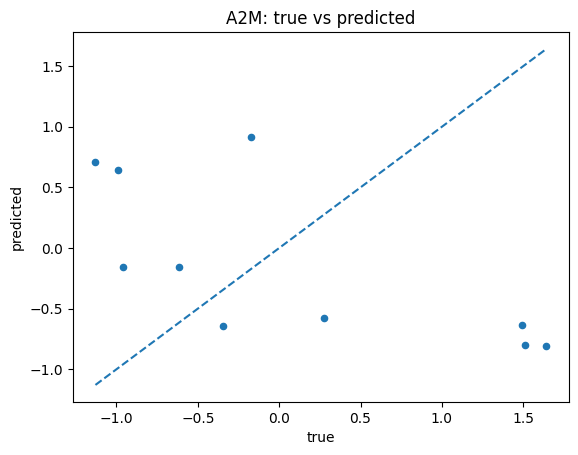

In [9]:

print("Predictions:")
display(predictions_df)

metric_rows = []
for key, value in metrics.items():
    if isinstance(value, (dict, list, tuple)):
        value = json.dumps(value, default=str)[:1000]
    metric_rows.append({"metric": key, "value": value})

print("Metrics:")
display(pd.DataFrame(metric_rows))

# Simple true-vs-predicted plot for quick visual sanity check.
try:
    import matplotlib.pyplot as plt
    ax = predictions_df.plot.scatter(x="true", y="predicted", title=f"{TARGET_PROTEIN}: true vs predicted")
    lims = [
        np.nanmin([predictions_df["true"].min(), predictions_df["predicted"].min()]),
        np.nanmax([predictions_df["true"].max(), predictions_df["predicted"].max()]),
    ]
    if np.all(np.isfinite(lims)) and lims[0] != lims[1]:
        ax.plot(lims, lims, linestyle="--")
    plt.show()
except Exception as exc:
    print(f"Plot skipped: {type(exc).__name__}: {exc}")



## 5. Save outputs to files

The notebook saves both machine-readable joblib files and easy-to-open views (`.csv`, `.json`, `.txt`).


In [10]:

def safe_name(value):
    value = str(value)
    value = re.sub(r"[^A-Za-z0-9_.-]+", "_", value)
    return value[:160].strip("_") or "protein"

def json_simplify(obj):
    """Convert nested objects into JSON-friendly summaries."""
    if isinstance(obj, dict):
        return {str(k): json_simplify(v) for k, v in obj.items() if k != "model"}
    if isinstance(obj, (list, tuple)):
        return [json_simplify(v) for v in obj]
    if isinstance(obj, np.ndarray):
        if obj.size <= 25:
            return obj.tolist()
        return {"array_shape": list(obj.shape), "dtype": str(obj.dtype), "preview": obj.ravel()[:10].tolist()}
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (pd.Index,)):
        return list(map(str, obj[:25]))
    if isinstance(obj, (pd.Series,)):
        return obj.head(25).to_dict()
    if isinstance(obj, (pd.DataFrame,)):
        return obj.head(25).to_dict(orient="records")
    try:
        json.dumps(obj)
        return obj
    except TypeError:
        return str(obj)

def artifact_summary(artifact):
    if artifact is None:
        return None
    summary = {}
    for key, value in artifact.items():
        if key == "model":
            summary[key] = str(type(value))
        elif key == "normalizer":
            summary[key] = {
                "method": value.get("method") if isinstance(value, dict) else str(type(value)),
                "columns_count": len(value.get("columns", [])) if isinstance(value, dict) else None,
            }
        elif key == "selected_features":
            summary["selected_feature_count"] = len(value)
            summary["selected_features_preview"] = list(map(str, value[:25]))
        elif key == "training_samples":
            summary["training_sample_count"] = len(value)
            summary["training_samples_preview"] = list(map(str, value[:25]))
        elif key == "feature_importance_gain":
            if isinstance(value, dict):
                top_items = sorted(value.items(), key=lambda kv: kv[1], reverse=True)[:25]
                summary["feature_importance_gain_top25"] = top_items
            else:
                summary[key] = json_simplify(value)
        else:
            summary[key] = json_simplify(value)
    return summary

OUT_DIR = DATA_DIR / "notebook_trial_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

prefix = safe_name(TARGET_PROTEIN) + "_subset_smoke_test"

paths = {
    "predictions_joblib": OUT_DIR / f"{prefix}_predictions.joblib",
    "predictions_csv": OUT_DIR / f"{prefix}_predictions.csv",
    "metrics_joblib": OUT_DIR / f"{prefix}_metrics.joblib",
    "metrics_json": OUT_DIR / f"{prefix}_metrics.json",
    "best_loo_model_joblib": OUT_DIR / f"{prefix}_best_loo_model.joblib",
    "best_loo_model_summary_json": OUT_DIR / f"{prefix}_best_loo_model_summary.json",
    "final_model_joblib": OUT_DIR / f"{prefix}_final_all_samples_model.joblib",
    "final_model_summary_json": OUT_DIR / f"{prefix}_final_all_samples_model_summary.json",
    "run_summary_txt": OUT_DIR / f"{prefix}_run_summary.txt",
}

# Predictions and metrics.
dump(predictions_df, paths["predictions_joblib"], compress=("gzip", 9))
predictions_df.to_csv(paths["predictions_csv"], index=False)
dump(metrics, paths["metrics_joblib"], compress=("gzip", 9))
paths["metrics_json"].write_text(json.dumps(json_simplify(metrics), indent=2), encoding="utf-8")

# Model artifacts.
if best_loo_model_artifact is not None:
    dump(best_loo_model_artifact, paths["best_loo_model_joblib"], compress=("gzip", 9))
    paths["best_loo_model_summary_json"].write_text(
        json.dumps(artifact_summary(best_loo_model_artifact), indent=2), encoding="utf-8"
    )
if final_model_artifact is not None:
    dump(final_model_artifact, paths["final_model_joblib"], compress=("gzip", 9))
    paths["final_model_summary_json"].write_text(
        json.dumps(artifact_summary(final_model_artifact), indent=2), encoding="utf-8"
    )

summary_lines = [
    f"Run timestamp: {datetime.now().isoformat(timespec='seconds')}",
    f"Protein: {TARGET_PROTEIN}",
    f"X shape: {X.shape}",
    f"Y shape: {Y.shape}",
    f"MAX_SAMPLES: {MAX_SAMPLES}",
    f"SELECT_K_EFFECTIVE: {SELECT_K_EFFECTIVE}",
    f"SPLITS: {SPLITS}",
    f"NORMALIZATION: {NORMALIZATION}",
    f"TUNING_STRATEGY: {TUNING_STRATEGY}",
    "",
    "Key metrics:",
]
for key in ["n_loo_predictions", "n_valid_predictions", "mse", "rmse", "pearson_corr", "mean_absolute_error"]:
    summary_lines.append(f"  {key}: {metrics.get(key)}")
paths["run_summary_txt"].write_text("\n".join(summary_lines), encoding="utf-8")

file_rows = []
for label, path in paths.items():
    if path.exists():
        file_rows.append({
            "label": label,
            "path": str(path),
            "size_kb": round(path.stat().st_size / 1024, 2),
            "modified": datetime.fromtimestamp(path.stat().st_mtime).isoformat(timespec="seconds"),
        })

files_df = pd.DataFrame(file_rows).sort_values("label")
print(f"Saved outputs in: {OUT_DIR}")
display(files_df)

print("Download/open links:")
for _, row in files_df.iterrows():
    display(FileLink(row["path"], result_html_prefix=f"{row['label']}: "))


Saved outputs in: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data\notebook_trial_outputs


,label,path,size_kb,modified
4,best_loo_model_joblib,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,4.45,2026-11-03T12:58:44
5,best_loo_model_summary_json,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,2.93,2026-11-03T12:58:44
6,final_model_joblib,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,4.42,2026-11-03T12:58:44
7,final_model_summary_json,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,2.40,2026-11-03T12:58:44
2,metrics_joblib,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,0.80,2026-11-03T12:58:44
3,metrics_json,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,1.83,2026-11-03T12:58:44
1,predictions_csv,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,12.56,2026-11-03T12:58:44
0,predictions_joblib,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,4.77,2026-11-03T12:58:44
8,run_summary_txt,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,0.38,2026-11-03T12:58:44


Download/open links:


C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data\notebook_trial_outputs\A2M_subset_smoke_test_best_loo_model.joblib

C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data\notebook_trial_outputs\A2M_subset_smoke_test_best_loo_model_summary.json

C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data\notebook_trial_outputs\A2M_subset_smoke_test_final_all_samples_model.joblib

... (2 outputs left out)

C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data\notebook_trial_outputs\A2M_subset_smoke_test_metrics.json

C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data\notebook_trial_outputs\A2M_subset_smoke_test_predictions.csv

C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data\notebook_trial_outputs\A2M_subset_smoke_test_predictions.joblib

C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. xgb\data\notebook_trial_outputs\A2M_subset_smoke_test_run_summary.txt


## 6. Reload saved files and show file views

This verifies the saved files can be opened and gives a compact view of each output.


In [11]:

def show_json_file(path, max_chars=4000):
    path = Path(path)
    print(f"--- {path.name} ---")
    text = path.read_text(encoding="utf-8")
    print(text[:max_chars])
    if len(text) > max_chars:
        print(f"\n... truncated, full file has {len(text)} characters")

def show_joblib_file(path):
    path = Path(path)
    print(f"--- {path.name} ---")
    obj = load(path)
    if isinstance(obj, pd.DataFrame):
        print(f"DataFrame shape: {obj.shape}")
        display(obj.head(20))
    elif isinstance(obj, dict):
        # Avoid displaying the raw model object in full.
        rows = []
        for key, value in obj.items():
            if key == "model":
                shown = str(type(value))
            elif key == "selected_features":
                shown = f"{len(value)} features; first 10 = {list(map(str, value[:10]))}"
            elif key == "training_samples":
                shown = f"{len(value)} samples; first 10 = {list(map(str, value[:10]))}"
            elif isinstance(value, dict):
                shown = json.dumps(json_simplify(value), default=str)[:1000]
            else:
                shown = str(json_simplify(value))[:1000]
            rows.append({"key": key, "value_preview": shown})
        display(pd.DataFrame(rows))
    else:
        print(type(obj))
        display(obj)

# Predictions joblib view
show_joblib_file(paths["predictions_joblib"])

# Metrics JSON view
show_json_file(paths["metrics_json"])

# Artifact summary views, if present
if paths["best_loo_model_summary_json"].exists():
    show_json_file(paths["best_loo_model_summary_json"])
if paths["final_model_summary_json"].exists():
    show_json_file(paths["final_model_summary_json"])


--- A2M_subset_smoke_test_predictions.joblib ---
DataFrame shape: (10, 9)


,protein,LOO sample,true,predicted,squared_error,absolute_error,params_dict,features_coef_dict,features_selected
0,A2M,MDAMB468_BREAST,-0.345562,-0.645173,0.089767,0.299611,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'AP002381.2': 0.4623626470565796, 'MAGEA1': 0...","[AP002381.2, MAGEA1, EPHB6, ADA, BX664615.1, F..."
1,A2M,SH4_SKIN,1.642186,-0.808224,6.004510,2.450410,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'TMEM65': 0.5228551626205444, 'LRFN4': 0.4044...","[TMEM65, LRFN4, PMS2P2, PTK6, RNF213, RPS8, AO..."
2,A2M,AU565_BREAST,-1.129114,0.708779,3.377850,1.837893,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'CLDN6': 0.581768810749054, 'ADIRF-AS1': 0.98...","[CLDN6, ADIRF-AS1, CDK20, SUCO, SULF2, TENM1, ..."
3,A2M,KMRC1_KIDNEY,1.493333,-0.636895,4.537872,2.130228,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'NFATC2': 0.4995092749595642, 'PTK6': 2.62871...","[NFATC2, PTK6, CLPP, CPB2-AS1, POLDIP3, SESN3,..."
4,A2M,CAL51_BREAST,0.274652,-0.575181,0.722216,0.849833,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'BX664615.1': 0.9650657773017883, 'AC020765.2...","[BX664615.1, AC020765.2, AP002381.2, RPS8, ZC3..."
5,A2M,RPMI7951_SKIN,-0.615667,-0.158565,0.208942,0.457101,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'AP002381.2': 0.5781771540641785, 'COA1': 1.4...","[AP002381.2, COA1, TMEM63C, ADA, GAD1, POLR3GL..."
6,A2M,RERFLCMS_LUNG,-0.957249,-0.152740,0.647234,0.804509,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'AP002381.2': 0.49043944478034973, 'ADA': 0.7...","[AP002381.2, ADA, TENM1, HIBADH, C11orf45, COA..."
7,A2M,IGR37_SKIN,-0.174494,0.914899,1.186778,1.089393,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'AP002381.2': 0.8025718331336975, 'HIBADH': 0...","[AP002381.2, HIBADH, CCDC144NL-AS1, AC092687.3..."
8,A2M,VMRCRCW_KIDNEY,-0.987932,0.644830,2.665910,1.632762,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'LDHC': 0.370148241519928, 'CPNE4': 1.1725062...","[LDHC, CPNE4, MAGEA1, LRP11, ADAMTS20, COX7B2,..."
9,A2M,HEP3B217_LIVER,1.513325,-0.801959,5.360540,2.315284,"{'max_depth': 2, 'min_child_weight': 1, 'learn...","{'DAGLB': 0.5115885734558105, 'IL4R': 0.564192...","[DAGLB, IL4R, AP3B1, LINC01376, PTK6, ADGRL3, ..."


--- A2M_subset_smoke_test_metrics.json ---
{
  "n_loo_predictions": 10,
  "n_valid_predictions": 10,
  "mse": 2.480161937753614,
  "rmse": 1.5748529892512553,
  "pearson_corr": -0.7042263824308299,
  "vector_cosine_similarity_all_loo": -0.6992556035760247,
  "mean_cosine_similarity_across_loo_iters": -0.4,
  "mean_absolute_error": 1.3867024343366043,
  "protein": "A2M",
  "proteomics_orientation": "proteins_as_columns_legacy",
  "normalization": "none",
  "select_k": 50,
  "grid_preset": "notebook_tiny",
  "tuning_strategy": "once",
  "n_splits_inner_cv": 3,
  "early_stopping_rounds": 10,
  "max_param_combos": 1,
  "use_gpu": false,
  "xgb_threads": 1,
  "minimal_summary_save": false,
  "summary_model": "final",
  "best_loo_model_summary": {
    "held_out_sample": "MDAMB468_BREAST",
    "true": -0.34556221985445,
    "predicted": -0.6451733708381653,
    "squared_error": 0.08976684179378663,
    "absolute_error": 0.29961115098371527,
    "params": {
      "max_depth": 2,
      "min_chi


## 7. Optional: test prediction with the saved final artifact

This cell reloads the final model artifact and predicts on a few raw transcriptomics rows. It checks that deployment-style prediction works via `predict_with_artifact`.


In [12]:

if paths["final_model_joblib"].exists():
    final_artifact_reloaded = load(paths["final_model_joblib"])
    X_new_demo = X.iloc[:5].copy()
    demo_pred = predict_with_artifact(final_artifact_reloaded, X_new_demo)
    display(demo_pred.to_frame())
else:
    print("Final artifact was not saved, so prediction demo is skipped.")


,A2M
samples,
MDAMB468_BREAST,-0.282370
SH4_SKIN,1.383886
AU565_BREAST,-0.841665
KMRC1_KIDNEY,1.262484
CAL51_BREAST,0.186951



## Notes for scaling up after the smoke test

Recommended next changes, one at a time:

1. Increase `MAX_SAMPLES` from `10` to `25` or more.
2. Increase `SELECT_K` from `50` to `500`.
3. Use a larger `PARAM_GRID`, or import `build_param_grid` from your runner script.
4. Switch `TUNING_STRATEGY = "nested"` for strict nested LOO tuning.
5. Increase `XGB_THREADS` if running on a workstation or SLURM allocation.


In [14]:
# Multi-protein smoke test: a few proteins with enough non-missing values in the first MAX_SAMPLES samples
N_PROTEINS = 5                      # change as needed
min_needed = max(3, int(SPLITS) + 1)

protein_axis = Y.columns if detected_orientation == "proteins_as_columns" else Y.index
TARGET_PROTEINS = [p for p in protein_axis
                   if _non_missing_count_for_candidate(p, MAX_SAMPLES) >= min_needed][:N_PROTEINS]
print(f"Proteins taken from Y.{'columns' if detected_orientation == 'proteins_as_columns' else 'index'}:",
      TARGET_PROTEINS)

all_summary_rows, failures = [], {}
for protein in TARGET_PROTEINS:
    print("=" * 80)
    print(f"Running protein: {protein}")
    try:
        result_i = pf.cv_pipeline_loo(
            model=None,
            param_grid=PARAM_GRID,
            X=X,
            y=Y,
            protein_name=str(protein),
            n_splits=int(SPLITS),
            n_samples=int(MAX_SAMPLES),
            select_k=int(SELECT_K_EFFECTIVE),
            early_stopping_rounds=int(EARLY_STOPPING),
            minimal_save=True,
            max_param_combos=1,
            use_gpu=bool(USE_GPU),
            normalization=str(NORMALIZATION),
            tuning_strategy="once",
            xgb_threads=int(XGB_THREADS) if XGB_THREADS is not None else None,
            grid_preset="notebook_tiny",
            save_models=True,
            save_final_model=True,
            minimal_summary_save=True,
            summary_model="final",
        )
        all_summary_rows.append(result_i["summary_row"])
    except Exception as e:
        failures[protein] = f"{type(e).__name__}: {e}"
        print(f"FAILED for {protein}: {failures[protein]}")

if not all_summary_rows:
    raise RuntimeError(f"All {len(TARGET_PROTEINS)} proteins failed:\n" +
                       "\n".join(f"  {p}: {msg}" for p, msg in failures.items()))

multi_summary_df = pd.concat(all_summary_rows, ignore_index=True)
cols = ["protein", "pearson_corr", "mse", "rmse", "cosine_similarity", "mean_absolute_error",
        "n_loo_predictions", "model_artifact_kind", "model_selected_feature_count"]
display(multi_summary_df[[c for c in cols if c in multi_summary_df.columns]])
print(f"\n{len(all_summary_rows)} succeeded, {len(failures)} failed.")

Proteins taken from Y.columns: ['A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1']
Running protein: A2M
Tuning hyperparameters once for this protein...
Best once-tuned params: {'max_depth': 2, 'min_child_weight': 1, 'learning_rate': 0.1, 'n_estimators': 25, 'subsample': 0.9, 'colsample_bytree': 0.8, 'gamma': 0.0, 'reg_alpha': 0.0, 'reg_lambda': 1.0, 'max_bin': 256, 'tree_method': 'hist', 'device': 'cpu', '_cv_median_best_iteration': 19, '_cv_mse': 0.7655875782171886}
LOO 1/10: held-out sample=MDAMB468_BREAST
LOO 2/10: held-out sample=SH4_SKIN
LOO 3/10: held-out sample=AU565_BREAST
LOO 4/10: held-out sample=KMRC1_KIDNEY
LOO 5/10: held-out sample=CAL51_BREAST
LOO 6/10: held-out sample=RPMI7951_SKIN
LOO 7/10: held-out sample=RERFLCMS_LUNG
LOO 8/10: held-out sample=IGR37_SKIN
LOO 9/10: held-out sample=VMRCRCW_KIDNEY
LOO 10/10: held-out sample=HEP3B217_LIVER
Running protein: AAAS
Tuning hyperparameters once for this protein...
Best once-tuned params: {'max_depth': 2, 'min_child_weight': 1, 'learning_r

,protein,pearson_corr,mse,rmse,cosine_similarity,n_loo_predictions,model_artifact_kind,model_selected_feature_count
0,A2M,-0.704226,2.480162,1.574853,-0.699256,10,final_all_samples_model,50
1,AAAS,0.369603,0.124299,0.352561,0.348112,10,final_all_samples_model,50
2,AACS,0.088313,0.349146,0.590886,0.086448,10,final_all_samples_model,50
3,AAGAB,-0.015460,0.177150,0.420892,-0.014861,10,final_all_samples_model,50
4,AAK1,0.118738,0.240800,0.490714,0.114825,10,final_all_samples_model,50



5 succeeded, 0 failed.
